In [41]:
import numpy as np
%pip install lime
import lime
import torch
from tokenizers import Tokenizer
from collections import OrderedDict
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools
from sklearn.metrics import precision_recall_fscore_support
from datasets import load_dataset, concatenate_datasets, DatasetDict


root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [42]:
topics = ["stance_abortion", "stance_atheism", "stance_climate", "stance_feminist", "stance_hillary"]

per_topic = [load_dataset("cardiffnlp/tweet_eval", t) for t in topics]

# all topics
dataset = DatasetDict({
    split: concatenate_datasets([ds[split] for ds in per_topic])
    for split in ["train", "validation", "test"]
})
# 1 topic
# dataset = per_topic[0]

dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})
# 1 topic
# dataset = load_dataset("cardiffnlp/tweet_eval", topics[0])

# Recover the original topic for each test tweet
# Uses the same ordering as concatenate_datasets()

topic_labels = [
    topic.replace("stance_", "")
    for topic, ds in zip(topics, per_topic)
    for _ in range(len(ds["test"]))
]

assert len(topic_labels) == len(dataset["test"])

if "topic" not in dataset["test"].column_names:
    dataset["test"] = dataset["test"].add_column(
        "topic", topic_labels
    )

In [43]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer, corpus: 'list[str]'):
        self.tokenizer = tokenizer
        self.corpus = corpus
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.corpus)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for text in self.corpus:
            unique_token_ids = set(self.tokenizer.encode(text).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [44]:
#tokenizer
vocab_size = 1000
min_frequency = 2
comb_dataset = concatenate_datasets([dataset["train"], dataset["validation"]])
corpus = [text for text in comb_dataset["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [45]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(comb_dataset["text"], comb_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [46]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [47]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [48]:
outcome_space = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [49]:
classifiers = OrderedDict()
MLP_PARAMS = {
    "hidden_dim": 128,
    "dropout": 0.1,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "num_epochs": 100,
}
LOGISTIC_PARAMS = {"max_iter": 100}
rope = 0.005


In [50]:
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer, corpus)

In [51]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args=LOGISTIC_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [52]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.682 seconds
Dataloader done! Time taken: 0.027 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 1.0377 | train acc: 0.4633 | val loss: 1.0148 | val acc: 0.4751
Epoch 02 | train loss: 0.9053 | train acc: 0.5418 | val loss: 0.9497 | val acc: 0.5437
Epoch 03 | train loss: 0.7425 | train acc: 0.7203 | val loss: 0.9098 | val acc: 0.5437
Epoch 04 | train loss: 0.5827 | train acc: 0.7971 | val loss: 0.9019 | val acc: 0.5952
Epoch 05 | train loss: 0.4669 | train acc: 0.8481 | val loss: 0.9370 | val acc: 0.6055
Epoch 06 | train loss: 0.3728 | train acc: 0.8880 | val loss: 0.9756 | val acc: 0.5986
Epoch 07 | train loss: 0.2993 | train acc: 0.9155 | val loss: 1.0281 | val acc: 0.5866
Epoch 08 | train loss: 0.2360 | train acc: 0.9532 | val loss: 1.0797 | val acc: 0.5969
Epoch 09 | train loss: 0.1916 | train acc: 0.9704 | val loss: 1.1436 | val acc: 0.5798
Epoch 10 | train loss: 0.1560 | train acc: 0.9794 | val loss: 1.1808 | val acc: 0.5935
Epoch 11 | train loss: 0.1245 | train acc: 0.9906 | val loss: 1.2467 | val acc: 0.5901
Epoch 12 | train loss: 0.1002 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0414 | train acc: 0.4620 | val loss: 1.0127 | val acc: 0.4648
Epoch 02 | train loss: 0.9084 | train acc: 0.5328 | val loss: 0.9371 | val acc: 0.5455
Epoch 03 | train loss: 0.7478 | train acc: 0.7117 | val loss: 0.8744 | val acc: 0.6141
Epoch 04 | train loss: 0.5951 | train acc: 0.8014 | val loss: 0.8612 | val acc: 0.6106
Epoch 05 | train loss: 0.4727 | train acc: 0.8576 | val loss: 0.8607 | val acc: 0.6261
Epoch 06 | train loss: 0.3780 | train acc: 0.9013 | val loss: 0.9021 | val acc: 0.6278
Epoch 07 | train loss: 0.3030 | train acc: 0.9301 | val loss: 0.9258 | val acc: 0.6192
Epoch 08 | train loss: 0.2355 | train acc: 0.9622 | val loss: 0.9667 | val acc: 0.6278
Epoch 09 | train loss: 0.1891 | train acc: 0.9730 | val loss: 0.9965 | val acc: 0.6192
Epoch 10 | train loss: 0.1478 | train acc: 0.9837 | val loss: 1.0516 | val acc: 0.6175
Epoch 11 | train loss: 0.1206 | train acc: 0.9897 | val loss: 1.0953 | val acc: 0.6175
Epoch 12 | train loss: 0.0965 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0440 | train acc: 0.4674 | val loss: 1.0102 | val acc: 0.4691
Epoch 02 | train loss: 0.9152 | train acc: 0.5274 | val loss: 0.9357 | val acc: 0.5361
Epoch 03 | train loss: 0.7477 | train acc: 0.7191 | val loss: 0.8774 | val acc: 0.6134
Epoch 04 | train loss: 0.5884 | train acc: 0.7946 | val loss: 0.8642 | val acc: 0.6048
Epoch 05 | train loss: 0.4660 | train acc: 0.8585 | val loss: 0.8849 | val acc: 0.6048
Epoch 06 | train loss: 0.3759 | train acc: 0.8889 | val loss: 0.9130 | val acc: 0.6031
Epoch 07 | train loss: 0.2975 | train acc: 0.9275 | val loss: 0.9564 | val acc: 0.6031
Epoch 08 | train loss: 0.2396 | train acc: 0.9541 | val loss: 1.0064 | val acc: 0.6031
Epoch 09 | train loss: 0.1893 | train acc: 0.9760 | val loss: 1.0507 | val acc: 0.6048
Epoch 10 | train loss: 0.1527 | train acc: 0.9858 | val loss: 1.1007 | val acc: 0.5962
Epoch 11 | train loss: 0.1232 | train acc: 0.9889 | val loss: 1.1477 | val acc: 0.5911
Epoch 12 | train loss: 0.1018 | train acc: 

In [53]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.604 seconds
Dataloader done! Time taken: 0.017 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0473 | train acc: 0.4689 | val loss: 1.0277 | val acc: 0.4751
Epoch 02 | train loss: 0.9179 | train acc: 0.5187 | val loss: 0.9260 | val acc: 0.5575
Epoch 03 | train loss: 0.6372 | train acc: 0.7443 | val loss: 0.9471 | val acc: 0.5695
Epoch 04 | train loss: 0.3631 | train acc: 0.8739 | val loss: 1.0978 | val acc: 0.5986
Epoch 05 | train loss: 0.1814 | train acc: 0.9511 | val loss: 1.2908 | val acc: 0.5832
Epoch 06 | train loss: 0.0796 | train acc: 0.9880 | val loss: 1.5017 | val acc: 0.5883
Epoch 07 | train loss: 0.0386 | train acc: 0.9953 | val loss: 1.6350 | val acc: 0.5815
Epoch 08 | train loss: 0.0248 | train acc: 0.9979 | val loss: 1.7550 | val acc: 0.5815
Epoch 09 | train loss: 0.0203 | train acc: 0.9974 | val loss: 1.8393 | val acc: 0.5901
Epoch 10 | train loss: 0.0144 | train acc: 0.9987 | val loss: 1.9321 | val acc: 0.5798
Epoch 11 | train loss: 0.0093 | train acc: 0.9987 | val loss: 2.0293 | val acc: 0.5849
Epoch 12 | train loss: 0.0068 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0511 | train acc: 0.4569 | val loss: 1.0044 | val acc: 0.5026
Epoch 02 | train loss: 0.9302 | train acc: 0.5264 | val loss: 0.9025 | val acc: 0.5849
Epoch 03 | train loss: 0.6433 | train acc: 0.7443 | val loss: 0.9242 | val acc: 0.5918
Epoch 04 | train loss: 0.3736 | train acc: 0.8692 | val loss: 1.0343 | val acc: 0.5815
Epoch 05 | train loss: 0.1958 | train acc: 0.9451 | val loss: 1.2093 | val acc: 0.5746
Epoch 06 | train loss: 0.0884 | train acc: 0.9858 | val loss: 1.4359 | val acc: 0.5746
Epoch 07 | train loss: 0.0449 | train acc: 0.9944 | val loss: 1.6158 | val acc: 0.5866
Epoch 08 | train loss: 0.0280 | train acc: 0.9970 | val loss: 1.7385 | val acc: 0.5763
Epoch 09 | train loss: 0.0186 | train acc: 0.9979 | val loss: 1.8641 | val acc: 0.5849
Epoch 10 | train loss: 0.0152 | train acc: 0.9987 | val loss: 1.9539 | val acc: 0.5918
Epoch 11 | train loss: 0.0096 | train acc: 0.9991 | val loss: 2.0202 | val acc: 0.5849
Epoch 12 | train loss: 0.0090 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0501 | train acc: 0.4702 | val loss: 1.0298 | val acc: 0.4648
Epoch 02 | train loss: 0.9233 | train acc: 0.5337 | val loss: 0.9198 | val acc: 0.5557
Epoch 03 | train loss: 0.6507 | train acc: 0.7327 | val loss: 0.8748 | val acc: 0.6398
Epoch 04 | train loss: 0.3747 | train acc: 0.8764 | val loss: 1.0000 | val acc: 0.6192
Epoch 05 | train loss: 0.1852 | train acc: 0.9567 | val loss: 1.1440 | val acc: 0.6312
Epoch 06 | train loss: 0.0778 | train acc: 0.9897 | val loss: 1.3150 | val acc: 0.6226
Epoch 07 | train loss: 0.0407 | train acc: 0.9961 | val loss: 1.4642 | val acc: 0.6226
Epoch 08 | train loss: 0.0227 | train acc: 0.9983 | val loss: 1.5980 | val acc: 0.6226
Epoch 09 | train loss: 0.0142 | train acc: 0.9991 | val loss: 1.6728 | val acc: 0.6158
Epoch 10 | train loss: 0.0117 | train acc: 0.9991 | val loss: 1.7460 | val acc: 0.6106
Epoch 11 | train loss: 0.0072 | train acc: 0.9996 | val loss: 1.7856 | val acc: 0.6158
Epoch 12 | train loss: 0.0063 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0492 | train acc: 0.4734 | val loss: 1.0290 | val acc: 0.4691
Epoch 02 | train loss: 0.9254 | train acc: 0.5292 | val loss: 0.9403 | val acc: 0.5034
Epoch 03 | train loss: 0.6548 | train acc: 0.7466 | val loss: 0.9164 | val acc: 0.5790
Epoch 04 | train loss: 0.3815 | train acc: 0.8709 | val loss: 1.0500 | val acc: 0.5756
Epoch 05 | train loss: 0.2021 | train acc: 0.9490 | val loss: 1.2031 | val acc: 0.5893
Epoch 06 | train loss: 0.1020 | train acc: 0.9798 | val loss: 1.4153 | val acc: 0.5859
Epoch 07 | train loss: 0.0449 | train acc: 0.9961 | val loss: 1.5541 | val acc: 0.5790
Epoch 08 | train loss: 0.0239 | train acc: 0.9974 | val loss: 1.6506 | val acc: 0.5928
Epoch 09 | train loss: 0.0151 | train acc: 0.9991 | val loss: 1.7765 | val acc: 0.5928
Epoch 10 | train loss: 0.0124 | train acc: 0.9996 | val loss: 1.8425 | val acc: 0.5928
Epoch 11 | train loss: 0.0089 | train acc: 0.9996 | val loss: 1.9232 | val acc: 0.5876
Epoch 12 | train loss: 0.0074 | train acc: 

In [54]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args=LOGISTIC_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [55]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.620 seconds
Dataloader done! Time taken: 0.017 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0403 | train acc: 0.4775 | val loss: 1.0151 | val acc: 0.4854
Epoch 02 | train loss: 0.9066 | train acc: 0.5495 | val loss: 0.9541 | val acc: 0.5369
Epoch 03 | train loss: 0.7365 | train acc: 0.7284 | val loss: 0.9061 | val acc: 0.5763
Epoch 04 | train loss: 0.5817 | train acc: 0.7984 | val loss: 0.9169 | val acc: 0.5849
Epoch 05 | train loss: 0.4603 | train acc: 0.8593 | val loss: 0.9525 | val acc: 0.5763
Epoch 06 | train loss: 0.3670 | train acc: 0.9026 | val loss: 0.9977 | val acc: 0.5798
Epoch 07 | train loss: 0.2961 | train acc: 0.9335 | val loss: 1.0596 | val acc: 0.5780
Epoch 08 | train loss: 0.2355 | train acc: 0.9571 | val loss: 1.1130 | val acc: 0.5712
Epoch 09 | train loss: 0.1869 | train acc: 0.9734 | val loss: 1.1728 | val acc: 0.5729
Epoch 10 | train loss: 0.1472 | train acc: 0.9850 | val loss: 1.2320 | val acc: 0.5746
Epoch 11 | train loss: 0.1202 | train acc: 0.9914 | val loss: 1.2846 | val acc: 0.5746
Epoch 12 | train loss: 0.0970 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0426 | train acc: 0.4668 | val loss: 0.9845 | val acc: 0.5060
Epoch 02 | train loss: 0.9028 | train acc: 0.5590 | val loss: 0.9197 | val acc: 0.5695
Epoch 03 | train loss: 0.7387 | train acc: 0.7113 | val loss: 0.8735 | val acc: 0.5866
Epoch 04 | train loss: 0.5828 | train acc: 0.7928 | val loss: 0.8903 | val acc: 0.5832
Epoch 05 | train loss: 0.4681 | train acc: 0.8563 | val loss: 0.9156 | val acc: 0.5780
Epoch 06 | train loss: 0.3728 | train acc: 0.8983 | val loss: 0.9586 | val acc: 0.5746
Epoch 07 | train loss: 0.3000 | train acc: 0.9301 | val loss: 1.0020 | val acc: 0.5660
Epoch 08 | train loss: 0.2365 | train acc: 0.9592 | val loss: 1.0481 | val acc: 0.5729
Epoch 09 | train loss: 0.1896 | train acc: 0.9734 | val loss: 1.0982 | val acc: 0.5798
Epoch 10 | train loss: 0.1553 | train acc: 0.9837 | val loss: 1.1508 | val acc: 0.5626
Epoch 11 | train loss: 0.1238 | train acc: 0.9871 | val loss: 1.1946 | val acc: 0.5643
Epoch 12 | train loss: 0.1015 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0325 | train acc: 0.4736 | val loss: 1.0091 | val acc: 0.4717
Epoch 02 | train loss: 0.8933 | train acc: 0.5603 | val loss: 0.9385 | val acc: 0.5437
Epoch 03 | train loss: 0.7334 | train acc: 0.7100 | val loss: 0.8911 | val acc: 0.6021
Epoch 04 | train loss: 0.5843 | train acc: 0.8001 | val loss: 0.8870 | val acc: 0.6141
Epoch 05 | train loss: 0.4680 | train acc: 0.8507 | val loss: 0.8990 | val acc: 0.6003
Epoch 06 | train loss: 0.3750 | train acc: 0.8936 | val loss: 0.9276 | val acc: 0.5918
Epoch 07 | train loss: 0.2988 | train acc: 0.9314 | val loss: 0.9749 | val acc: 0.6021
Epoch 08 | train loss: 0.2356 | train acc: 0.9567 | val loss: 1.0049 | val acc: 0.5918
Epoch 09 | train loss: 0.1878 | train acc: 0.9751 | val loss: 1.0605 | val acc: 0.5952
Epoch 10 | train loss: 0.1491 | train acc: 0.9858 | val loss: 1.0942 | val acc: 0.5918
Epoch 11 | train loss: 0.1204 | train acc: 0.9918 | val loss: 1.1378 | val acc: 0.6072
Epoch 12 | train loss: 0.1002 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0356 | train acc: 0.4807 | val loss: 1.0153 | val acc: 0.4759
Epoch 02 | train loss: 0.9047 | train acc: 0.5429 | val loss: 0.9440 | val acc: 0.5309
Epoch 03 | train loss: 0.7380 | train acc: 0.7191 | val loss: 0.8891 | val acc: 0.5945
Epoch 04 | train loss: 0.5855 | train acc: 0.7946 | val loss: 0.8925 | val acc: 0.6048
Epoch 05 | train loss: 0.4683 | train acc: 0.8576 | val loss: 0.9010 | val acc: 0.5945
Epoch 06 | train loss: 0.3740 | train acc: 0.8954 | val loss: 0.9396 | val acc: 0.6100
Epoch 07 | train loss: 0.2936 | train acc: 0.9322 | val loss: 0.9840 | val acc: 0.6065
Epoch 08 | train loss: 0.2334 | train acc: 0.9558 | val loss: 1.0350 | val acc: 0.6134
Epoch 09 | train loss: 0.1848 | train acc: 0.9708 | val loss: 1.0854 | val acc: 0.6168
Epoch 10 | train loss: 0.1478 | train acc: 0.9850 | val loss: 1.1320 | val acc: 0.6065
Epoch 11 | train loss: 0.1197 | train acc: 0.9893 | val loss: 1.1712 | val acc: 0.6031
Epoch 12 | train loss: 0.0963 | train acc: 

In [56]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.709 seconds
Dataloader done! Time taken: 0.019 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0510 | train acc: 0.4620 | val loss: 1.0274 | val acc: 0.4751
Epoch 02 | train loss: 0.9223 | train acc: 0.5337 | val loss: 0.9343 | val acc: 0.5369
Epoch 03 | train loss: 0.6629 | train acc: 0.7289 | val loss: 0.9716 | val acc: 0.5712
Epoch 04 | train loss: 0.3887 | train acc: 0.8584 | val loss: 1.0852 | val acc: 0.5746
Epoch 05 | train loss: 0.1869 | train acc: 0.9537 | val loss: 1.3046 | val acc: 0.5626
Epoch 06 | train loss: 0.0894 | train acc: 0.9828 | val loss: 1.5119 | val acc: 0.5678
Epoch 07 | train loss: 0.0470 | train acc: 0.9944 | val loss: 1.6940 | val acc: 0.5712
Epoch 08 | train loss: 0.0259 | train acc: 0.9979 | val loss: 1.8491 | val acc: 0.5695
Epoch 09 | train loss: 0.0152 | train acc: 0.9991 | val loss: 1.9337 | val acc: 0.5609
Epoch 10 | train loss: 0.0157 | train acc: 0.9987 | val loss: 2.0421 | val acc: 0.5489
Epoch 11 | train loss: 0.0149 | train acc: 0.9974 | val loss: 2.0876 | val acc: 0.5506
Epoch 12 | train loss: 0.0073 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0507 | train acc: 0.4629 | val loss: 1.0041 | val acc: 0.5026
Epoch 02 | train loss: 0.9325 | train acc: 0.5174 | val loss: 0.9051 | val acc: 0.5815
Epoch 03 | train loss: 0.6573 | train acc: 0.7413 | val loss: 0.9364 | val acc: 0.5660
Epoch 04 | train loss: 0.3848 | train acc: 0.8696 | val loss: 1.1237 | val acc: 0.5626
Epoch 05 | train loss: 0.1965 | train acc: 0.9468 | val loss: 1.3184 | val acc: 0.5643
Epoch 06 | train loss: 0.0929 | train acc: 0.9828 | val loss: 1.5306 | val acc: 0.5678
Epoch 07 | train loss: 0.0457 | train acc: 0.9949 | val loss: 1.7013 | val acc: 0.5678
Epoch 08 | train loss: 0.0241 | train acc: 0.9983 | val loss: 1.8306 | val acc: 0.5643
Epoch 09 | train loss: 0.0179 | train acc: 0.9979 | val loss: 1.9370 | val acc: 0.5712
Epoch 10 | train loss: 0.0131 | train acc: 0.9983 | val loss: 2.0295 | val acc: 0.5695
Epoch 11 | train loss: 0.0109 | train acc: 0.9991 | val loss: 2.1007 | val acc: 0.5660
Epoch 12 | train loss: 0.0086 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0436 | train acc: 0.4826 | val loss: 1.0269 | val acc: 0.4648
Epoch 02 | train loss: 0.9043 | train acc: 0.5358 | val loss: 0.9533 | val acc: 0.5609
Epoch 03 | train loss: 0.6329 | train acc: 0.7516 | val loss: 0.9710 | val acc: 0.5918
Epoch 04 | train loss: 0.3563 | train acc: 0.8850 | val loss: 1.1033 | val acc: 0.5832
Epoch 05 | train loss: 0.1748 | train acc: 0.9618 | val loss: 1.2747 | val acc: 0.5798
Epoch 06 | train loss: 0.0763 | train acc: 0.9888 | val loss: 1.4715 | val acc: 0.5643
Epoch 07 | train loss: 0.0388 | train acc: 0.9966 | val loss: 1.7109 | val acc: 0.5643
Epoch 08 | train loss: 0.0227 | train acc: 0.9974 | val loss: 1.8277 | val acc: 0.5695
Epoch 09 | train loss: 0.0149 | train acc: 0.9979 | val loss: 1.8864 | val acc: 0.5678
Epoch 10 | train loss: 0.0097 | train acc: 0.9996 | val loss: 1.9961 | val acc: 0.5695
Epoch 11 | train loss: 0.0083 | train acc: 0.9996 | val loss: 2.0443 | val acc: 0.5695
Epoch 12 | train loss: 0.0056 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0474 | train acc: 0.4683 | val loss: 1.0234 | val acc: 0.4691
Epoch 02 | train loss: 0.9157 | train acc: 0.5236 | val loss: 0.9396 | val acc: 0.5430
Epoch 03 | train loss: 0.6700 | train acc: 0.7307 | val loss: 0.9184 | val acc: 0.6014
Epoch 04 | train loss: 0.4054 | train acc: 0.8619 | val loss: 1.0168 | val acc: 0.6014
Epoch 05 | train loss: 0.2166 | train acc: 0.9357 | val loss: 1.1956 | val acc: 0.5979
Epoch 06 | train loss: 0.1047 | train acc: 0.9794 | val loss: 1.3171 | val acc: 0.5790
Epoch 07 | train loss: 0.0490 | train acc: 0.9940 | val loss: 1.4886 | val acc: 0.5945
Epoch 08 | train loss: 0.0263 | train acc: 0.9970 | val loss: 1.6446 | val acc: 0.5859
Epoch 09 | train loss: 0.0167 | train acc: 0.9987 | val loss: 1.7389 | val acc: 0.5945
Epoch 10 | train loss: 0.0114 | train acc: 0.9991 | val loss: 1.8115 | val acc: 0.5997
Epoch 11 | train loss: 0.0087 | train acc: 0.9991 | val loss: 1.8749 | val acc: 0.5928
Epoch 12 | train loss: 0.0073 | train acc: 

In [57]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args=LOGISTIC_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, catego

In [58]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.725 seconds
Dataloader done! Time taken: 0.020 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0753 | train acc: 0.4620 | val loss: 1.0501 | val acc: 0.4751
Epoch 02 | train loss: 1.0243 | train acc: 0.4796 | val loss: 1.0264 | val acc: 0.4751
Epoch 03 | train loss: 0.9687 | train acc: 0.4916 | val loss: 0.9881 | val acc: 0.4854
Epoch 04 | train loss: 0.8785 | train acc: 0.5890 | val loss: 0.9390 | val acc: 0.5557
Epoch 05 | train loss: 0.7799 | train acc: 0.7139 | val loss: 0.9030 | val acc: 0.5780
Epoch 06 | train loss: 0.6906 | train acc: 0.7572 | val loss: 0.8997 | val acc: 0.5798
Epoch 07 | train loss: 0.6267 | train acc: 0.7756 | val loss: 0.8954 | val acc: 0.5798
Epoch 08 | train loss: 0.5722 | train acc: 0.7979 | val loss: 0.9024 | val acc: 0.5918
Epoch 09 | train loss: 0.5244 | train acc: 0.8220 | val loss: 0.9166 | val acc: 0.5798
Epoch 10 | train loss: 0.4870 | train acc: 0.8331 | val loss: 0.9437 | val acc: 0.5798
Epoch 11 | train loss: 0.4558 | train acc: 0.8426 | val loss: 0.9660 | val acc: 0.5832
Epoch 12 | train loss: 0.4266 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0679 | train acc: 0.4728 | val loss: 1.0336 | val acc: 0.5026
Epoch 02 | train loss: 1.0223 | train acc: 0.4728 | val loss: 1.0024 | val acc: 0.5026
Epoch 03 | train loss: 0.9670 | train acc: 0.4775 | val loss: 0.9631 | val acc: 0.5317
Epoch 04 | train loss: 0.8767 | train acc: 0.5856 | val loss: 0.9110 | val acc: 0.5901
Epoch 05 | train loss: 0.7717 | train acc: 0.7164 | val loss: 0.8756 | val acc: 0.5866
Epoch 06 | train loss: 0.6861 | train acc: 0.7508 | val loss: 0.8634 | val acc: 0.5849
Epoch 07 | train loss: 0.6145 | train acc: 0.7851 | val loss: 0.8711 | val acc: 0.5729
Epoch 08 | train loss: 0.5672 | train acc: 0.8035 | val loss: 0.8881 | val acc: 0.5798
Epoch 09 | train loss: 0.5228 | train acc: 0.8207 | val loss: 0.9086 | val acc: 0.5746
Epoch 10 | train loss: 0.4877 | train acc: 0.8344 | val loss: 0.9345 | val acc: 0.5729
Epoch 11 | train loss: 0.4545 | train acc: 0.8477 | val loss: 0.9609 | val acc: 0.5729
Epoch 12 | train loss: 0.4300 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0706 | train acc: 0.4513 | val loss: 1.0510 | val acc: 0.4648
Epoch 02 | train loss: 1.0175 | train acc: 0.4822 | val loss: 1.0282 | val acc: 0.4648
Epoch 03 | train loss: 0.9639 | train acc: 0.4878 | val loss: 0.9854 | val acc: 0.4854
Epoch 04 | train loss: 0.8806 | train acc: 0.5783 | val loss: 0.9319 | val acc: 0.5678
Epoch 05 | train loss: 0.7821 | train acc: 0.7057 | val loss: 0.8987 | val acc: 0.5969
Epoch 06 | train loss: 0.6976 | train acc: 0.7460 | val loss: 0.8761 | val acc: 0.6175
Epoch 07 | train loss: 0.6299 | train acc: 0.7683 | val loss: 0.8654 | val acc: 0.6072
Epoch 08 | train loss: 0.5749 | train acc: 0.8031 | val loss: 0.8707 | val acc: 0.5986
Epoch 09 | train loss: 0.5322 | train acc: 0.8108 | val loss: 0.8871 | val acc: 0.5969
Epoch 10 | train loss: 0.4927 | train acc: 0.8293 | val loss: 0.9004 | val acc: 0.5935
Epoch 11 | train loss: 0.4614 | train acc: 0.8370 | val loss: 0.9213 | val acc: 0.6021
Epoch 12 | train loss: 0.4352 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0676 | train acc: 0.4816 | val loss: 1.0500 | val acc: 0.4691
Epoch 02 | train loss: 1.0197 | train acc: 0.4811 | val loss: 1.0271 | val acc: 0.4691
Epoch 03 | train loss: 0.9644 | train acc: 0.4850 | val loss: 0.9898 | val acc: 0.4777
Epoch 04 | train loss: 0.8769 | train acc: 0.5819 | val loss: 0.9409 | val acc: 0.5309
Epoch 05 | train loss: 0.7749 | train acc: 0.7063 | val loss: 0.9072 | val acc: 0.5567
Epoch 06 | train loss: 0.6892 | train acc: 0.7547 | val loss: 0.8911 | val acc: 0.6031
Epoch 07 | train loss: 0.6206 | train acc: 0.7779 | val loss: 0.8940 | val acc: 0.5893
Epoch 08 | train loss: 0.5708 | train acc: 0.7890 | val loss: 0.9040 | val acc: 0.5859
Epoch 09 | train loss: 0.5264 | train acc: 0.8186 | val loss: 0.9197 | val acc: 0.5859
Epoch 10 | train loss: 0.4908 | train acc: 0.8293 | val loss: 0.9430 | val acc: 0.5790
Epoch 11 | train loss: 0.4603 | train acc: 0.8435 | val loss: 0.9648 | val acc: 0.5808
Epoch 12 | train loss: 0.4302 | train acc: 

In [59]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=tfidf_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args=MLP_PARAMS
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.735 seconds
Dataloader done! Time taken: 0.019 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0583 | train acc: 0.4796 | val loss: 1.0448 | val acc: 0.4751
Epoch 02 | train loss: 1.0027 | train acc: 0.4796 | val loss: 0.9952 | val acc: 0.4768
Epoch 03 | train loss: 0.8641 | train acc: 0.5830 | val loss: 0.9386 | val acc: 0.5540
Epoch 04 | train loss: 0.6973 | train acc: 0.7366 | val loss: 0.9520 | val acc: 0.5609
Epoch 05 | train loss: 0.5377 | train acc: 0.8121 | val loss: 1.0066 | val acc: 0.5678
Epoch 06 | train loss: 0.4013 | train acc: 0.8644 | val loss: 1.0960 | val acc: 0.5798
Epoch 07 | train loss: 0.2995 | train acc: 0.9082 | val loss: 1.2212 | val acc: 0.5763
Epoch 08 | train loss: 0.2247 | train acc: 0.9352 | val loss: 1.3482 | val acc: 0.5557
Epoch 09 | train loss: 0.1544 | train acc: 0.9648 | val loss: 1.4859 | val acc: 0.5592
Epoch 10 | train loss: 0.1019 | train acc: 0.9854 | val loss: 1.6365 | val acc: 0.5660
Epoch 11 | train loss: 0.0671 | train acc: 0.9936 | val loss: 1.8232 | val acc: 0.5643
Epoch 12 | train loss: 0.0455 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0785 | train acc: 0.4243 | val loss: 1.0291 | val acc: 0.5026
Epoch 02 | train loss: 1.0247 | train acc: 0.4728 | val loss: 0.9902 | val acc: 0.5026
Epoch 03 | train loss: 0.9277 | train acc: 0.4981 | val loss: 0.9136 | val acc: 0.5592
Epoch 04 | train loss: 0.7508 | train acc: 0.7143 | val loss: 0.8857 | val acc: 0.5798
Epoch 05 | train loss: 0.5547 | train acc: 0.8031 | val loss: 0.9480 | val acc: 0.5729
Epoch 06 | train loss: 0.4179 | train acc: 0.8554 | val loss: 1.0647 | val acc: 0.5626
Epoch 07 | train loss: 0.3137 | train acc: 0.9009 | val loss: 1.1889 | val acc: 0.5849
Epoch 08 | train loss: 0.2324 | train acc: 0.9387 | val loss: 1.3339 | val acc: 0.5523
Epoch 09 | train loss: 0.1631 | train acc: 0.9640 | val loss: 1.4539 | val acc: 0.5609
Epoch 10 | train loss: 0.1088 | train acc: 0.9798 | val loss: 1.5988 | val acc: 0.5557
Epoch 11 | train loss: 0.0729 | train acc: 0.9901 | val loss: 1.7362 | val acc: 0.5540
Epoch 12 | train loss: 0.0498 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0615 | train acc: 0.4766 | val loss: 1.0540 | val acc: 0.4648
Epoch 02 | train loss: 1.0082 | train acc: 0.4822 | val loss: 1.0114 | val acc: 0.4648
Epoch 03 | train loss: 0.8872 | train acc: 0.5431 | val loss: 0.9215 | val acc: 0.5918
Epoch 04 | train loss: 0.6916 | train acc: 0.7396 | val loss: 0.9432 | val acc: 0.6089
Epoch 05 | train loss: 0.5132 | train acc: 0.8112 | val loss: 0.9368 | val acc: 0.5883
Epoch 06 | train loss: 0.3876 | train acc: 0.8683 | val loss: 1.0119 | val acc: 0.5952
Epoch 07 | train loss: 0.2974 | train acc: 0.9039 | val loss: 1.1648 | val acc: 0.5935
Epoch 08 | train loss: 0.2173 | train acc: 0.9387 | val loss: 1.2490 | val acc: 0.5901
Epoch 09 | train loss: 0.1493 | train acc: 0.9687 | val loss: 1.4060 | val acc: 0.5952
Epoch 10 | train loss: 0.1024 | train acc: 0.9846 | val loss: 1.5080 | val acc: 0.5935
Epoch 11 | train loss: 0.0717 | train acc: 0.9931 | val loss: 1.6557 | val acc: 0.5986
Epoch 12 | train loss: 0.0470 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0657 | train acc: 0.4648 | val loss: 1.0547 | val acc: 0.4691
Epoch 02 | train loss: 1.0084 | train acc: 0.4811 | val loss: 1.0105 | val acc: 0.4691
Epoch 03 | train loss: 0.8710 | train acc: 0.5652 | val loss: 0.9269 | val acc: 0.5430
Epoch 04 | train loss: 0.6626 | train acc: 0.7504 | val loss: 0.9365 | val acc: 0.5773
Epoch 05 | train loss: 0.4903 | train acc: 0.8225 | val loss: 1.0254 | val acc: 0.5979
Epoch 06 | train loss: 0.3702 | train acc: 0.8752 | val loss: 1.1302 | val acc: 0.5842
Epoch 07 | train loss: 0.2805 | train acc: 0.9198 | val loss: 1.2921 | val acc: 0.5842
Epoch 08 | train loss: 0.2050 | train acc: 0.9507 | val loss: 1.4383 | val acc: 0.5790
Epoch 09 | train loss: 0.1424 | train acc: 0.9751 | val loss: 1.5412 | val acc: 0.5704
Epoch 10 | train loss: 0.0994 | train acc: 0.9841 | val loss: 1.6879 | val acc: 0.5704
Epoch 11 | train loss: 0.0684 | train acc: 0.9927 | val loss: 1.8101 | val acc: 0.5687
Epoch 12 | train loss: 0.0487 | train acc: 

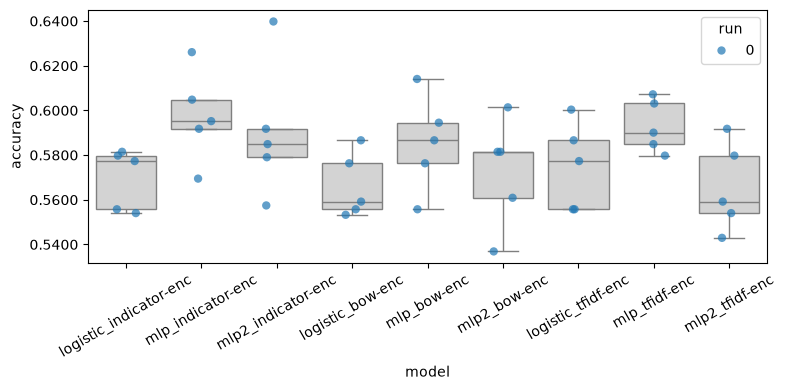

In [60]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [61]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.0135
P(Tie)    = 0.0248
P(B wins) = 0.9617
Effect Size = 2.89

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.0917
P(Tie)    = 0.0981
P(B wins) = 0.8102
Effect Size = 1.30

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.5437
P(Tie)    = 0.2065
P(B wins) = 0.2498
Effect Size = -0.43


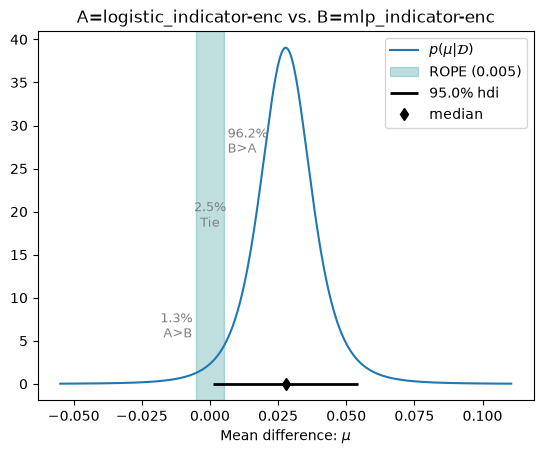

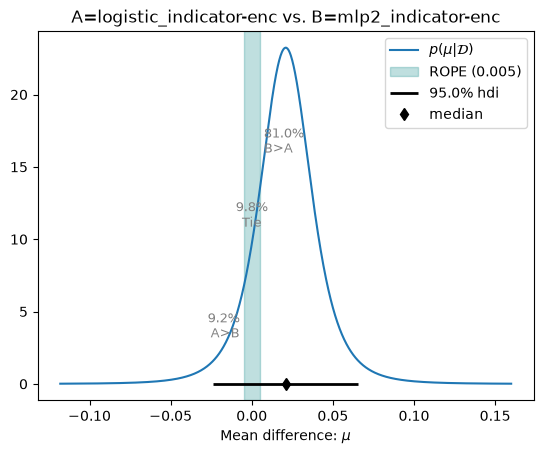

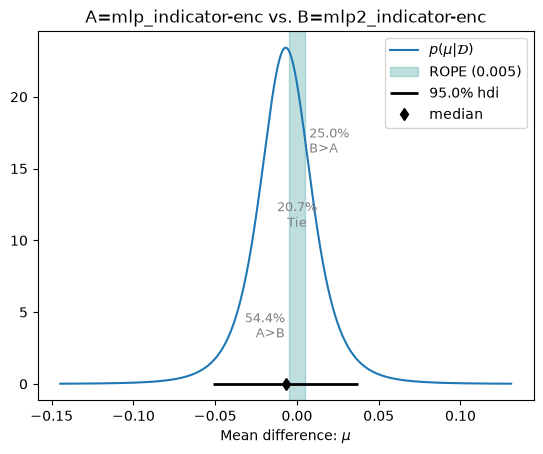

In [62]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [63]:

import Project1.smlp as smlp
import Project1.smlp2 as smlp2

# Find saved checkpoints from your cross-validation
def find_checkpoints(model_name):
    folder = results_folder / model_name / "seed-0"

    checkpoints = sorted(
        path.with_suffix("")
        for path in folder.rglob("*.pt")
        if path.with_suffix(".json").exists()
    )

    if not checkpoints:
        raise FileNotFoundError(
            f"No saved model checkpoints found in {folder}"
        )

    return checkpoints


mlp_checkpoints = find_checkpoints("mlp_indicator-enc")
mlp2_checkpoints = find_checkpoints("mlp2_indicator-enc")

print("Original MLP checkpoints:")
for i, path in enumerate(mlp_checkpoints):
    print(i, path)

print("\nModified MLP checkpoints:")
for i, path in enumerate(mlp2_checkpoints):
    print(i, path)


Original MLP checkpoints:
0 results/mlp_indicator-enc/seed-0/fold-0/model
1 results/mlp_indicator-enc/seed-0/fold-1/model
2 results/mlp_indicator-enc/seed-0/fold-2/model
3 results/mlp_indicator-enc/seed-0/fold-3/model
4 results/mlp_indicator-enc/seed-0/fold-4/model

Modified MLP checkpoints:
0 results/mlp2_indicator-enc/seed-0/fold-0/model
1 results/mlp2_indicator-enc/seed-0/fold-1/model
2 results/mlp2_indicator-enc/seed-0/fold-2/model
3 results/mlp2_indicator-enc/seed-0/fold-3/model
4 results/mlp2_indicator-enc/seed-0/fold-4/model


In [64]:
# Select corresponding checkpoints from the same fold
fold = 0

mlp_model = smlp.load(
    str(mlp_checkpoints[fold]),
    device="cpu"
)

mlp2_model = smlp2.load2(
    str(mlp2_checkpoints[fold]),
    device="cpu"
)

mlp_model.eval()
mlp2_model.eval()

print("Both MLP models loaded successfully!")

Both MLP models loaded successfully!


In [65]:
# Log-linear
def logistic_predict(texts, encoder):
    return Project1.loglin.predict_probs(
        texts,
        logistic_model,
        encoder
    )

for i, path in enumerate(mlp2_checkpoints):
    print(i, path)

# Original MLP
def mlp_predict(texts, encoder):
    return Project1.smlp.predict_probs(
        texts,
        mlp_model,
        encoder
    )

# Modified MLP (two hidden layers)
def mlp2_predict(texts, encoder):
    return Project1.smlp2.predict_probs2(
        texts,
        mlp2_model,
        encoder
    )

encoders = {token_indicator_encoder, bow_encoder, tfidf_encoder}

# Models for LIME
models = {
    "Log-linear": logistic_predict,
    "Original MLP": mlp_predict,
    "Modified MLP": mlp2_predict
}

0 results/mlp2_indicator-enc/seed-0/fold-0/model
1 results/mlp2_indicator-enc/seed-0/fold-1/model
2 results/mlp2_indicator-enc/seed-0/fold-2/model
3 results/mlp2_indicator-enc/seed-0/fold-3/model
4 results/mlp2_indicator-enc/seed-0/fold-4/model


In [66]:
tweet_id = 157
test_text = dataset["test"][tweet_id]
print(test_text)
print("Original MLP:", mlp_predict(test_text, token_indicator_encoder))
print("Modified MLP:", mlp2_predict(test_text, token_indicator_encoder))
print("Log-linear:", logistic_predict(test_text, token_indicator_encoder))

{'text': 'What about in cases of rape', 'label': 2, 'topic': 'abortion'}
Original MLP: [[0.34822235 0.34620506 0.30557266]
 [0.2814333  0.3083712  0.4101955 ]
 [0.37496656 0.29223612 0.33279726]]
Modified MLP: [[0.35511452 0.33117348 0.31371194]
 [0.31114483 0.35123792 0.3376173 ]
 [0.34145588 0.32262415 0.33592   ]]
Log-linear: [[0.47619126 0.27138742 0.25242132]
 [0.28615673 0.22019484 0.49364843]
 [0.34599551 0.3040239  0.34998059]]


Classes: [(0, 'none'), (1, 'against'), (2, 'favor')]
none: Selected tweet 146
against: Selected tweet 964
favor: Selected tweet 666
Topic: abortion
True stance: none
Tweet: To run outside? To run inside?

--- Log-linear ---
Prediction: none
Probabilities: [0.8505 0.1052 0.0443]
Explanation: [(np.str_('To'), 0.2749361792166039), (np.str_('outside'), 0.11801856660164439), (np.str_('inside'), -0.10486749091602961), (np.str_('run'), 0.09297877266203992)]


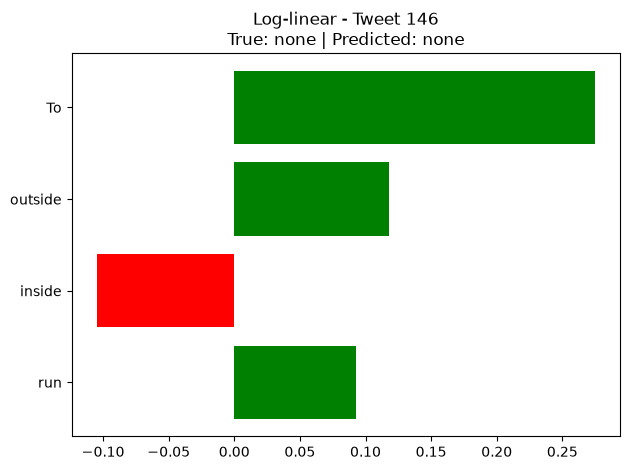


--- Original MLP ---
Prediction: none
Probabilities: [0.5449 0.3125 0.1426]
Explanation: [(np.str_('To'), 0.1272816241978581), (np.str_('outside'), 0.05765435829175857), (np.str_('run'), 0.02329319632126463), (np.str_('inside'), -0.006210924068714152)]


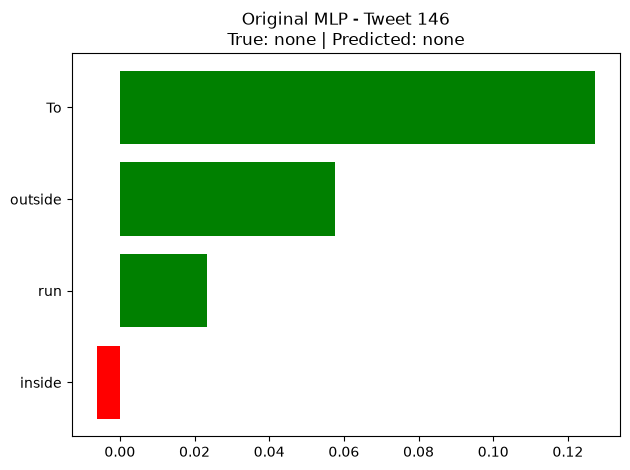


--- Modified MLP ---
Prediction: against
Probabilities: [0.3534 0.3812 0.2655]
Explanation: [(np.str_('To'), 0.026481476157185668), (np.str_('inside'), -0.018995774168128837), (np.str_('run'), -0.0031342610782614574), (np.str_('outside'), 0.0015323966940366366)]


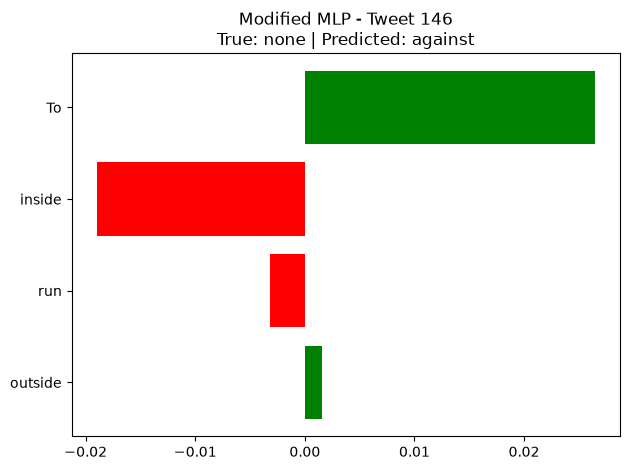

Topic: hillary
True stance: against
Tweet: @user @user The compliant media allowed themeselves to b herded by a couple of strands of rope? Good sheep!

--- Log-linear ---
Prediction: against
Probabilities: [0.0388 0.9591 0.0022]
Explanation: [(np.str_('couple'), 0.14804900308712438), (np.str_('user'), -0.10946447808014811), (np.str_('sheep'), 0.09969309110606818), (np.str_('themeselves'), 0.08627286104541436), (np.str_('herded'), 0.08588164957752943), (np.str_('compliant'), 0.08584373433240927), (np.str_('rope'), -0.058614012099427945), (np.str_('a'), 0.0519984187489332), (np.str_('strands'), -0.047462523095003636), (np.str_('to'), -0.04544559753736241)]


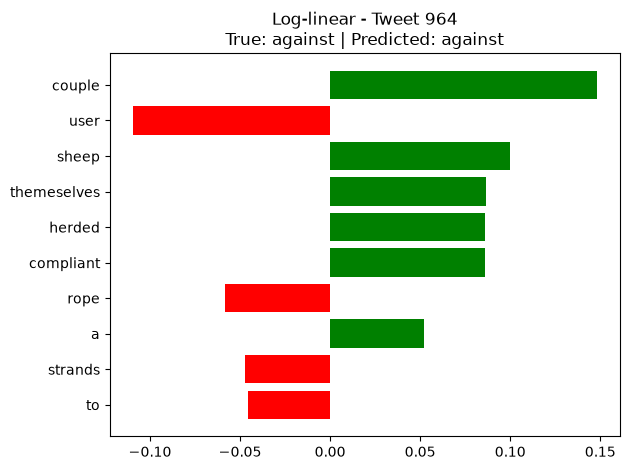


--- Original MLP ---
Prediction: against
Probabilities: [0.0745 0.837  0.0885]
Explanation: [(np.str_('themeselves'), 0.16358592665610913), (np.str_('sheep'), 0.11916133593988326), (np.str_('couple'), 0.07991673131378212), (np.str_('herded'), 0.07118455718595486), (np.str_('of'), 0.06668186067875864), (np.str_('to'), -0.05639930898568496), (np.str_('The'), 0.0536451878167283), (np.str_('rope'), -0.05256397115391632), (np.str_('compliant'), 0.051054457656644035), (np.str_('user'), -0.050492327151393276)]


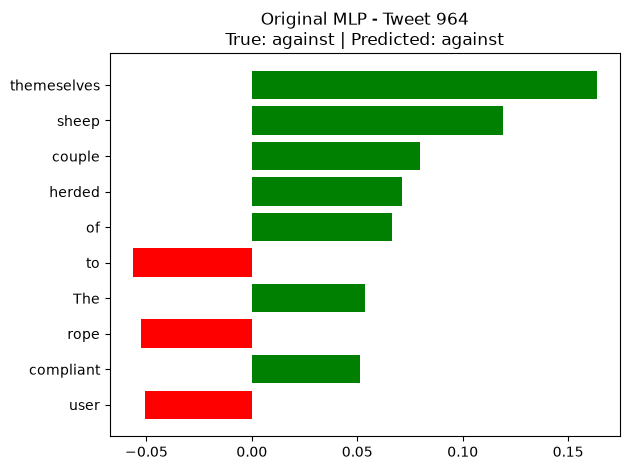


--- Modified MLP ---
Prediction: against
Probabilities: [0.183  0.6345 0.1825]
Explanation: [(np.str_('themeselves'), 0.10225116377377115), (np.str_('of'), 0.06177694973377206), (np.str_('couple'), 0.05883571148878904), (np.str_('sheep'), 0.05679390754186801), (np.str_('herded'), 0.04655485794697547), (np.str_('to'), -0.04586358515376779), (np.str_('allowed'), -0.036679710171815406), (np.str_('The'), 0.03642206218727565), (np.str_('rope'), -0.033447104483901986), (np.str_('strands'), 0.028174718864590984)]


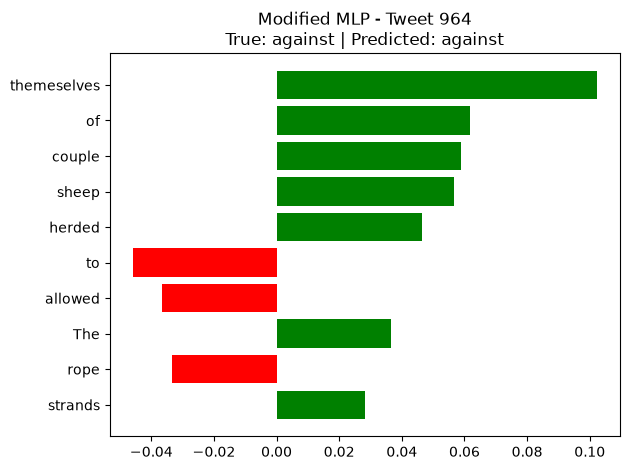

Topic: climate
True stance: favor
Tweet: If we touch #Antarctica for one more #reason other than to #research the #impact of us we would be #insane! #Democracy #Goal?

--- Log-linear ---
Prediction: against
Probabilities: [0.1065 0.8009 0.0926]
Explanation: [(np.str_('other'), -0.28126600577700395), (np.str_('Democracy'), -0.22145058455298108), (np.str_('reason'), 0.1396158763597756), (np.str_('would'), 0.11319423110306931), (np.str_('touch'), -0.09097810079551266), (np.str_('research'), 0.0738885622505439), (np.str_('to'), 0.07102087715173241), (np.str_('Antarctica'), -0.05662630261241309), (np.str_('the'), -0.05316744377421381), (np.str_('Goal'), 0.05306569590344028)]


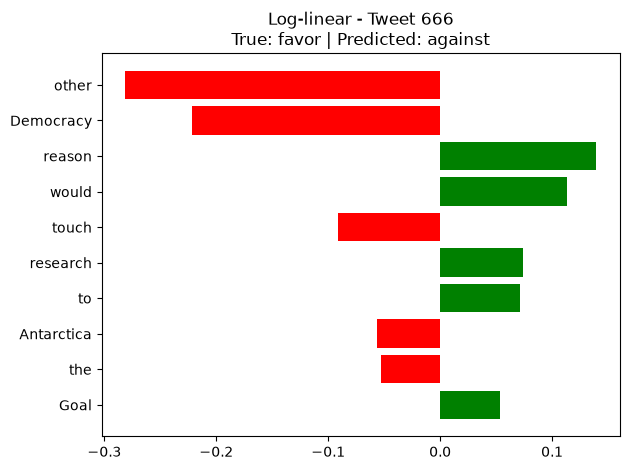


--- Original MLP ---
Prediction: against
Probabilities: [0.3924 0.5488 0.0587]
Explanation: [(np.str_('Democracy'), -0.1336143092301079), (np.str_('other'), -0.08076268749250899), (np.str_('reason'), 0.044703966261492284), (np.str_('us'), -0.03539778557714054), (np.str_('impact'), -0.03416598761298497), (np.str_('would'), 0.03310465630430402), (np.str_('touch'), -0.031528955953017766), (np.str_('the'), -0.02759902509571375), (np.str_('of'), -0.027445832472894057), (np.str_('to'), 0.02660329914406964)]


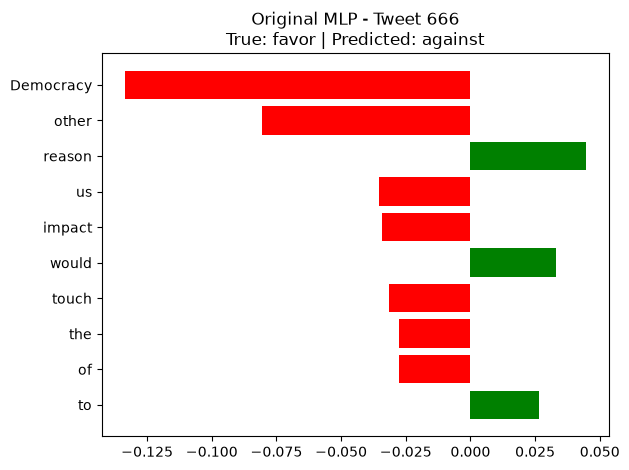


--- Modified MLP ---
Prediction: none
Probabilities: [0.4405 0.4021 0.1574]
Explanation: [(np.str_('Democracy'), -0.060503441372184635), (np.str_('the'), -0.028511845503498293), (np.str_('to'), 0.02822304972990558), (np.str_('other'), -0.02697811604524197), (np.str_('touch'), -0.024668613299447688), (np.str_('one'), -0.020940080828238724), (np.str_('insane'), -0.020214893345024788), (np.str_('of'), -0.01943913430220053), (np.str_('Antarctica'), -0.014057945034098584), (np.str_('If'), 0.013810559520842628)]


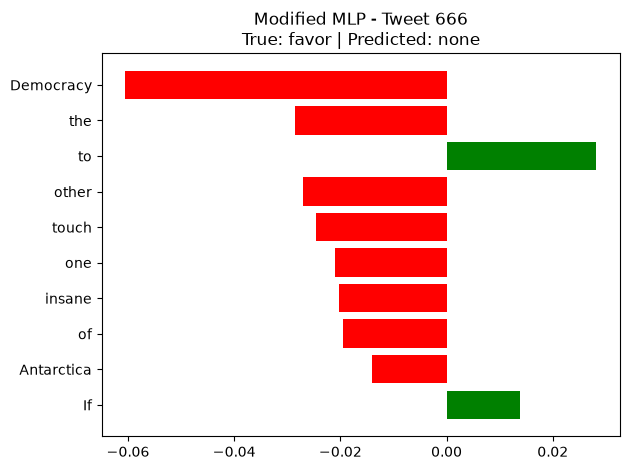

In [67]:

import numpy as np
import matplotlib.pyplot as plt
from lime.lime_text import LimeTextExplainer
from functools import partial

# ======================================================
# 1. SETUP LIME
# ======================================================

class_names = dataset["train"].features["label"].names
print("Classes:", list(enumerate(class_names)))

explainer = LimeTextExplainer(
    class_names=class_names,
    random_state=42
)

models = {
    "Log-linear": partial(
        logistic_predict, encoder=token_indicator_encoder
    ),
    "Original MLP": partial(
        mlp_predict, encoder=token_indicator_encoder
    ),
    "Modified MLP": partial(
        mlp2_predict, encoder=token_indicator_encoder
    )
}

# ======================================================
# 2. AUTOMATICALLY SELECT ONE TWEET PER CLASS
# ======================================================

rng = np.random.default_rng(42)

test_labels = np.array(dataset["test"]["label"])

tweets = []

for label_id, class_name in enumerate(class_names):

    # Find all test examples belonging to this class
    candidates = np.where(test_labels == label_id)[0]

    if len(candidates) == 0:
        print(f"No examples found for {class_name}")
        continue

    # Random, reproducible selection
    selected_id = int(rng.choice(candidates))
    tweets.append(selected_id)

    print(f"{class_name}: Selected tweet {selected_id}")

# ======================================================
# 3. EXPLAIN EACH TWEET WITH ALL THREE MODELS
# ======================================================



for tweet_id in tweets:

    example = dataset["test"][tweet_id]

    text = example["text"]
    topic = example["topic"]
    true_label = int(example["label"])

    print(f"Topic: {topic}")
    print(f"True stance: {class_names[true_label]}")
    print(f"Tweet: {text}")
    for model_name, predict_fn in models.items():

        # Encoder is already supplied through partial()
        probabilities = predict_fn([text])[0]
        predicted_label = int(np.argmax(probabilities))

        # Explain the same true class across all models
        exp = explainer.explain_instance(
            text,
            predict_fn,
            num_features=10,
            num_samples=1000,
            labels=(true_label,)
        )

        print(f"\n--- {model_name} ---")
        print("Prediction:", class_names[predicted_label])
        print("Probabilities:", probabilities.round(4))
        print(
            "Explanation:",
            exp.as_list(label=true_label)
        )

        fig = exp.as_pyplot_figure(label=true_label)
        plt.title(
            f"{model_name} - Tweet {tweet_id}\n"
            f"True: {class_names[true_label]} | "
            f"Predicted: {class_names[predicted_label]}"
        )
        plt.tight_layout()
        plt.show()


In [68]:
# Collect cross-validation accuracy measurements
model_scores = {
    "Log-linear": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "MLP": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "Modified MLP": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

# Check the shapes
for name, scores in model_scores.items():
    print(name, scores.shape)

# Bayesian comparisons
results = []

for name_a, name_b in itertools.combinations(model_scores.keys(), 2):

    scores_a = np.asarray(model_scores[name_a], dtype=float)
    scores_b = np.asarray(model_scores[name_b], dtype=float)

    assert scores_a.shape == scores_b.shape, (
        "The models must have the same number of paired measurements."
    )

    posterior = Project1.analysis.BenavoliCorrelatedT(
        scores_a,
        scores_b,
        runs=1,  # Change if you used repeated cross-validation
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)

display(df.round(4))


Log-linear (5,)
MLP (5,)
Modified MLP (5,)


,Model A,Model B,P(A wins),P(Tie),P(B wins),Effect Size
0,Log-linear,MLP,0.0135,0.0248,0.9617,2.8937
1,Log-linear,Modified MLP,0.0917,0.0981,0.8102,1.2968
2,MLP,Modified MLP,0.5437,0.2065,0.2498,-0.4291


In [69]:
for topic in topics:
    topic_dataset = load_dataset("cardiffnlp/tweet_eval", topic)
    topic_test = topic_dataset["test"]
    texts = list(topic_test["text"])
    real_y = [int(label) for label in topic_test["label"]]

    rows = []
    for encoder in encoders:
        predictions = {
            "Logistic": logistic_predict(texts, encoder),
            "MLP": mlp_predict(texts, encoder),
            "MLP2": mlp2_predict(texts, encoder),
        }
        for model_name, pred_y in predictions.items():
            pred_labels = np.argmax(pred_y, axis=1)
            precision, recall, f1, _ = precision_recall_fscore_support(
                real_y, pred_labels, average="weighted", zero_division=0
            )
            rows.append({
                "Encoder": encoder.__class__.__name__,
                "Model": model_name,
                "Precision": precision,
                "Recall": recall,
                "F1 Score": f1,
            })

    metrics_df = pd.DataFrame(rows).set_index(["Encoder", "Model"])
    print(f"\nMetrics for topic: {topic}")
    display(metrics_df.round(4))


Metrics for topic: stance_abortion


Precision  Recall  F1 Score
Encoder        Model                                
BagOfWords     Logistic     0.5742  0.5643    0.5682
               MLP          0.5940  0.6071    0.5988
               MLP2         0.6360  0.6750    0.6405
tfidf          Logistic     0.5803  0.4357    0.4585
               MLP          0.6242  0.5857    0.5969
               MLP2         0.6557  0.2964    0.2827
TokenIndicator Logistic     0.5783  0.5714    0.5733
               MLP          0.6263  0.6393    0.6273
               MLP2         0.6398  0.6786    0.6433


Metrics for topic: stance_atheism


Precision  Recall  F1 Score
Encoder        Model                                
BagOfWords     Logistic     0.6389  0.5818    0.6018
               MLP          0.6309  0.6409    0.6355
               MLP2         0.6740  0.7091    0.6841
tfidf          Logistic     0.6582  0.3273    0.3647
               MLP          0.6737  0.5773    0.6069
               MLP2         0.7507  0.2682    0.2754
TokenIndicator Logistic     0.6425  0.5818    0.6039
               MLP          0.6233  0.6591    0.6392
               MLP2         0.6691  0.6955    0.6697


Metrics for topic: stance_climate


Precision  Recall  F1 Score
Encoder        Model                                
BagOfWords     Logistic     0.6702  0.4911    0.5501
               MLP          0.6903  0.5030    0.5659
               MLP2         0.6960  0.3609    0.4385
tfidf          Logistic     0.7437  0.2899    0.2605
               MLP          0.6951  0.4556    0.5030
               MLP2         0.7713  0.2308    0.1283
TokenIndicator Logistic     0.6557  0.4793    0.5373
               MLP          0.6951  0.4911    0.5584
               MLP2         0.7330  0.3609    0.4333


Metrics for topic: stance_feminist


Precision  Recall  F1 Score
Encoder        Model                                
BagOfWords     Logistic     0.5942  0.5614    0.5748
               MLP          0.5590  0.5614    0.5595
               MLP2         0.5311  0.5719    0.5463
tfidf          Logistic     0.6110  0.3684    0.3914
               MLP          0.5777  0.4877    0.5146
               MLP2         0.6266  0.2281    0.1905
TokenIndicator Logistic     0.5915  0.5614    0.5742
               MLP          0.5928  0.5895    0.5873
               MLP2         0.5263  0.5754    0.5430


Metrics for topic: stance_hillary


Precision  Recall  F1 Score
Encoder        Model                                
BagOfWords     Logistic     0.5736  0.5932    0.5789
               MLP          0.5686  0.5898    0.5581
               MLP2         0.5652  0.6102    0.5499
tfidf          Logistic     0.5919  0.5356    0.5184
               MLP          0.5863  0.6068    0.5917
               MLP2         0.5408  0.3797    0.3218
TokenIndicator Logistic     0.5637  0.5864    0.5686
               MLP          0.6013  0.6034    0.5674
               MLP2         0.5747  0.6136    0.5540

Transforming documents...
Document transformation done! Time taken: 0.817 seconds
Dataloader done! Time taken: 0.033 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0404 | train acc: 0.4715 | val loss: 1.0167 | val acc: 0.4768
Epoch 02 | train loss: 0.9050 | train acc: 0.5307 | val loss: 0.9391 | val acc: 0.5575
Epoch 03 | train loss: 0.7320 | train acc: 0.7229 | val loss: 0.8892 | val acc: 0.5883
Epoch 04 | train loss: 0.5718 | train acc: 0.8095 | val loss: 0.9041 | val acc: 0.5969
Epoch 05 | train loss: 0.4537 | train acc: 0.8580 | val loss: 0.9346 | val acc: 0.6003
Epoch 06 | train loss: 0.3663 | train acc: 0.8936 | val loss: 0.9700 | val acc: 0.5935
Epoch 07 | train loss: 0.2873 | train acc: 0.9309 | val loss: 1.0337 | val acc: 0.5883
Epoch 08 | train loss: 0.2284 | train acc: 0.9597 | val loss: 1.0764 | val acc: 0.5918
Epoch 09 | train loss: 0.1814 | train acc: 0.9747 | val loss: 1.1225 | val acc: 0.5866
Epoch 10 | train loss: 0.1435 | train acc: 0.9863 | val loss: 1.1802 | val acc: 0.5901
Epoch 11 | train loss: 0.1182 | train acc: 0.9910 | val loss: 1.2235 | val acc: 0.5798
Epoch 12 | train loss: 0.0963 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0457 | train acc: 0.4796 | val loss: 1.0273 | val acc: 0.4751
Epoch 02 | train loss: 0.9056 | train acc: 0.5401 | val loss: 0.9207 | val acc: 0.5643
Epoch 03 | train loss: 0.6160 | train acc: 0.7576 | val loss: 0.9716 | val acc: 0.5849
Epoch 04 | train loss: 0.3614 | train acc: 0.8709 | val loss: 1.1250 | val acc: 0.6003
Epoch 05 | train loss: 0.1857 | train acc: 0.9477 | val loss: 1.3454 | val acc: 0.5815
Epoch 06 | train loss: 0.0866 | train acc: 0.9854 | val loss: 1.5581 | val acc: 0.5969
Epoch 07 | train loss: 0.0415 | train acc: 0.9957 | val loss: 1.7074 | val acc: 0.5866
Epoch 08 | train loss: 0.0245 | train acc: 0.9974 | val loss: 1.8462 | val acc: 0.5780
Epoch 09 | train loss: 0.0151 | train acc: 0.9987 | val loss: 2.0188 | val acc: 0.5763
Epoch 10 | train loss: 0.0116 | train acc: 0.9987 | val loss: 2.1286 | val acc: 0.5643
Epoch 11 | train loss: 0.0089 | train acc: 0.9991 | val loss: 2.1631 | val acc: 0.5815
Epoch 12 | train loss: 0.0088 | train acc: 

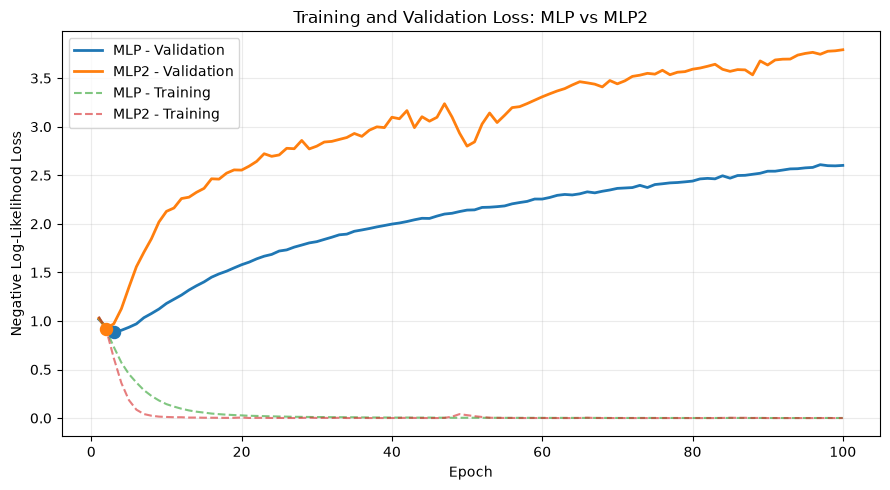

In [70]:
# Same training/validation fold for both architectures
fold_data = my_cross_validation_sets[0][0]

# Separate folder: don't overwrite original CV checkpoints
curve_folder = results_folder / "learning_curves"
curve_folder.mkdir(parents=True, exist_ok=True)

# Same hyperparameters as your original experiments
params = MLP_PARAMS

# Train original MLP
torch.manual_seed(42)
metrics_mlp, _, _ = smlp.train_neural_network_model(
    training_set=fold_data["training"],
    validation_set=fold_data["validation"],
    num_classes=len(outcome_space),
    encoder=token_indicator_encoder,
    save_to=str(curve_folder / "mlp"),
    **params
)

# Train modified MLP
torch.manual_seed(42)
metrics_mlp2, _, _ = smlp2.train_neural_network_model2(
    training_set=fold_data["training"],
    validation_set=fold_data["validation"],
    num_classes=len(outcome_space),
    encoder=token_indicator_encoder,
    save_to=str(curve_folder / "mlp2"),
    **params
)

# Extract losses
train_mlp = [m["train_metrics"]["loss"] for m in metrics_mlp]
val_mlp = [m["val_metrics"]["loss"] for m in metrics_mlp]

train_mlp2 = [m["train_metrics"]["loss"] for m in metrics_mlp2]
val_mlp2 = [m["val_metrics"]["loss"] for m in metrics_mlp2]

epochs = np.arange(1, len(val_mlp) + 1)

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(epochs, val_mlp, label="MLP - Validation", linewidth=2)
ax.plot(epochs, val_mlp2, label="MLP2 - Validation", linewidth=2)

ax.plot(epochs, train_mlp, "--", label="MLP - Training", alpha=0.6)
ax.plot(epochs, train_mlp2, "--", label="MLP2 - Training", alpha=0.6)

# Highlight best validation epoch
for name, losses, line_index in [
    ("MLP", val_mlp, 0),
    ("MLP2", val_mlp2, 1)
]:
    best = int(np.argmin(losses))
    color = ax.lines[line_index].get_color()

    ax.scatter(
        best + 1, losses[best],
        color=color, s=75, zorder=5
    )

    print(
        f"{name}: best epoch = {best + 1}, "
        f"minimum validation loss = {losses[best]:.4f}"
    )

ax.set_title("Training and Validation Loss: MLP vs MLP2")
ax.set_xlabel("Epoch")
ax.set_ylabel("Negative Log-Likelihood Loss")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("mlp_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()


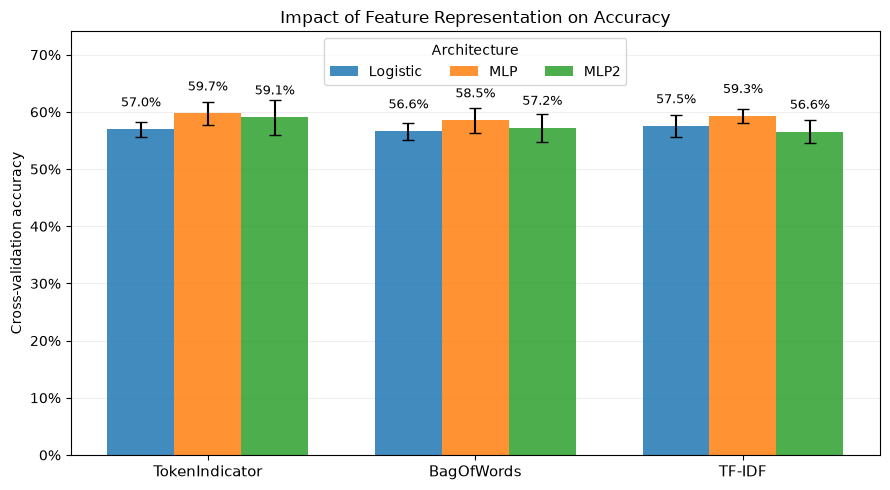

In [71]:
from matplotlib.ticker import PercentFormatter

# Get the existing cross-validation accuracy results
df = Project1.analysis.make_data_frame(classifiers).copy()

# Extract model and encoder names
df["Architecture"] = df["model"].str.extract(
    r"^(logistic|mlp2|mlp)_"
)[0].map({
    "logistic": "Logistic",
    "mlp": "MLP",
    "mlp2": "MLP2"
})

df["Encoder"] = df["model"].str.extract(
    r"_(indicator|bow|tfidf)-enc$"
)[0].map({
    "indicator": "TokenIndicator",
    "bow": "BagOfWords",
    "tfidf": "TF-IDF"
})

# Calculate mean and standard deviation across CV folds
summary = (
    df.groupby(["Encoder", "Architecture"])["accuracy"]
    .agg(["mean", "std"])
)

encoders = ["TokenIndicator", "BagOfWords", "TF-IDF"]
architectures = ["Logistic", "MLP", "MLP2"]

x = np.arange(len(encoders))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

for i, model in enumerate(architectures):
    means = [
        summary.loc[(enc, model), "mean"]
        for enc in encoders
    ]

    stds = [
        summary.loc[(enc, model), "std"]
        for enc in encoders
    ]

    positions = x + (i - 1) * width

    bars = ax.bar(
        positions,
        means,
        width,
        yerr=stds,
        capsize=4,
        label=model,
        alpha=0.85
    )

    # Display mean accuracy above each bar
    for bar, mean in zip(bars, means):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.04,
            f"{mean:.1%}",
            ha="center",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels(encoders, fontsize=11)

ax.set_ylabel("Cross-validation accuracy")
ax.set_title("Impact of Feature Representation on Accuracy")

ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, min(1.0, (summary["mean"] + summary["std"]).max() + 0.12))

ax.legend(title="Architecture", ncol=3, loc="upper center")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "encoder_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
